<!-- colab-badge -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Zeshengliu213/ai-for-materials/blob/main/02%20-%20Supervised%20Learning/02c_trees_and_ensembles.ipynb)

# 02c · 树模型与集成学习：决策树、随机森林与 XGBoost

在表格型材料与化学数据（描述符矩阵、配方工艺表）上，当今综合表现最强的经典机器学习算法既不是线性模型（`02a`），也不是距离/核模型（`02b`），而是基于**决策树（Decision Tree）**的**集成学习（Ensemble Learning）**家族——尤其是**随机森林（Random Forest）**与**梯度提升树（XGBoost）**。

它们为什么不需要特征缩放就能直接开工？几百棵树“民主投票”和“接力改错”有什么本质区别？为什么它们在测试集上精度极高，一去预测更大的并五苯却集体“卡壳”？本节我们从手算第一刀切分开始，把树模型彻底拆透。

### 本节内容
1. 决策树（CART）原理：手算最优切分阈值与深度为 2 的阶梯切分图
2. 单棵深树的过拟合诊断
3. 集成学习两大流派：**Bagging（随机森林：并行降方差）** vs **Boosting（XGBoost：串行拟合残差降偏差）**
4. 分子表示大比拼：17 个物理化学描述符 vs 二值/计数 Morgan 指纹
5. 实战推理：并苯系列（苯 $\to$ 并五苯）溶解度预测与**树模型外推盲区**本质

In [1]:
# colab-setup (本地运行时自动跳过)
import os, sys

if "google.colab" in sys.modules:
    _repo_dir = "/content/ai-for-materials"
    if not os.path.exists(_repo_dir):
        os.system("git clone --depth 1 https://github.com/Zeshengliu213/ai-for-materials.git " + _repo_dir)
    os.chdir(os.path.join(_repo_dir, "02 - Supervised Learning"))
    get_ipython().run_line_magic("pip", "install -q rdkit xgboost")


## 0. 环境准备与数据加载

In [2]:
try:
    import rdkit
except ImportError:
    %pip install -q rdkit
    import rdkit
try:
    import xgboost
except ImportError:
    %pip install -q xgboost
    import xgboost

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, rdFingerprintGenerator
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import root_mean_squared_error, r2_score

RDLogger.DisableLog("rdApp.*")

<!-- ai4m-style -->
> **📘 课程统一绘图风格**：下面这格加载课程自带的 `ai4m.mplstyle`（配色与课程网站同源，无上右边框，仅横向浅网格，保存默认 300 dpi）。`C` 是课程配色，手动指定颜色时写 `color=C.crimson`。


In [3]:
# ai4m-style：课程统一绘图风格（本地与 Colab 通用）
import pathlib, sys

sys.path.insert(0, str(pathlib.Path.cwd().parent))   # course/ 根目录
import ai4m_style as ai4m

C = ai4m.use()        # 应用 ai4m.mplstyle，返回课程配色


In [4]:
DATA_FILE = "data/solubility.csv" if os.path.exists("data/solubility.csv") else "../01 - Basics/data/solubility.csv"
df = pd.read_csv(DATA_FILE)
df["mol"] = df["SMILES"].apply(Chem.MolFromSmiles)
df = df[df["mol"].notna()].reset_index(drop=True)

feature_cols = [
    "MolWt", "MolLogP", "MolMR", "HeavyAtomCount", "NumHAcceptors", "NumHDonors",
    "NumHeteroatoms", "NumRotatableBonds", "NumValenceElectrons", "NumAromaticRings",
    "NumSaturatedRings", "NumAliphaticRings", "RingCount", "TPSA", "LabuteASA",
    "BalabanJ", "BertzCT",
]
X = df[feature_cols].values
y = df["Solubility"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def evaluate_reg(model, X_tr, y_tr, X_te, y_te, label="Model"):
    model.fit(X_tr, y_tr)
    tr_rmse = root_mean_squared_error(y_tr, model.predict(X_tr))
    te_pred = model.predict(X_te)
    te_rmse = root_mean_squared_error(y_te, te_pred)
    te_r2 = r2_score(y_te, te_pred)
    print(f"{label:28s} | 训练 RMSE = {tr_rmse:.3f} | 测试 RMSE = {te_rmse:.3f} | 测试 R² = {te_r2:.3f}")
    return te_rmse

---
## 1. 决策树（Decision Tree）原理：怎么挑出“第一刀”？

### 📘 1.1 二十个问题游戏与加权均方误差（MSE）准则

决策树就像做实验时的流程图：每次挑**一个特征 $j$** 和**一个阈值 $t$**，问一句“$\text{特征 } j \le t$ 吗？”，把当前这堆分子一分为二（左子集 $L$ 与右子集 $R$），最后拿每个叶子节点里所有训练分子 $\log S$ 的**平均值**作为预测输出。

> **💡 为什么所有树模型都不需要做 `StandardScaler` 特征缩放？**
> 因为询问“`MolWt <= 250`”与询问标准化后的“`MolWt_scaled <= 0.12`”分出来的左右两拨分子**一模一样**！单调线性缩放丝毫不改变特征的排序次序。

计算机凭什么决定第一刀切在哪个特征、哪个数值上？答案极其暴力而纯粹：**穷举每个特征的候选切分点，选让切开后左右两边内部最“纯净”（方差最小）的那一刀！**
- 在**回归树**中，用左右子节点的**加权均方误差（Weighted MSE）**衡量不纯度：
  $$J(j, t) = \frac{n_L}{n}\underbrace{\frac{1}{n_L}\sum_{i \in L}(y_i - \bar{y}_L)^2}_{\text{左子集方差}} + \frac{n_R}{n}\underbrace{\frac{1}{n_R}\sum_{i \in R}(y_i - \bar{y}_R)^2}_{\text{右子集方差}}$$
- （在下一节 `02d` 的**分类树**中，只需把方差换成**基尼不纯度 Gini Impurity** $G = 1 - \sum_k p_k^2$ 即可，逻辑完全相通。）

下面我们用 **12 行纯 NumPy** 亲手在 7584 个训练分子、17 个描述符中搜出全局最优的“第一刀”，看看和 `DecisionTreeRegressor(max_depth=1)` 是否完全一致：

In [5]:
# ▶️ 运行看看：手写 12 行 NumPy 搜索回归树根节点的最优切分特征与阈值
best_mse, best_feat, best_thresh = np.inf, None, None
n_total = len(y_train)

for j, fname in enumerate(feature_cols):
    col = X_train[:, j]
    # 在该特征的分位数候选点上测试一分为二后的加权 MSE
    for t in np.unique(np.percentile(col, np.linspace(2, 98, 97))):
        left = y_train[col <= t]
        right = y_train[col > t]
        if len(left) == 0 or len(right) == 0:
            continue
        weighted_mse = (len(left) * left.var() + len(right) * right.var()) / n_total
        if weighted_mse < best_mse:
            best_mse, best_feat, best_thresh = weighted_mse, fname, t

stump = DecisionTreeRegressor(max_depth=1, random_state=42).fit(X_train, y_train)
sk_feat = feature_cols[stump.tree_.feature[0]]
sk_thresh = stump.tree_.threshold[0]

print(f"手写搜索第一刀 -> 特征: {best_feat} <= {best_thresh:.2f} (加权 MSE = {best_mse:.3f})")
print(f"sklearn 精确解 -> 特征: {sk_feat} <= {sk_thresh:.2f} (加权 MSE = {stump.tree_.impurity[1]*stump.tree_.n_node_samples[1]/n_total + stump.tree_.impurity[2]*stump.tree_.n_node_samples[2]/n_total:.3f})")

手写搜索第一刀 -> 特征: MolLogP <= 2.80 (加权 MSE = 3.097)
sklearn 精确解 -> 特征: MolLogP <= 2.75 (加权 MSE = 3.092)


果不其然，在全部 17 个物理化学描述符中，决策树一眼相中的第一刀正是疏水常数 **`MolLogP`**！

### ▶️ 运行看看：深度为 2 的阶梯切分图 vs 不限深度的死记硬背

如果只在 `MolLogP` 上切两层（`max_depth=2`，共 $2^2 = 4$ 个叶子），预测函数长什么样？如果不限制深度（`max_depth=None`）任由它一直切到每个叶子里只剩 1 个分子呢？

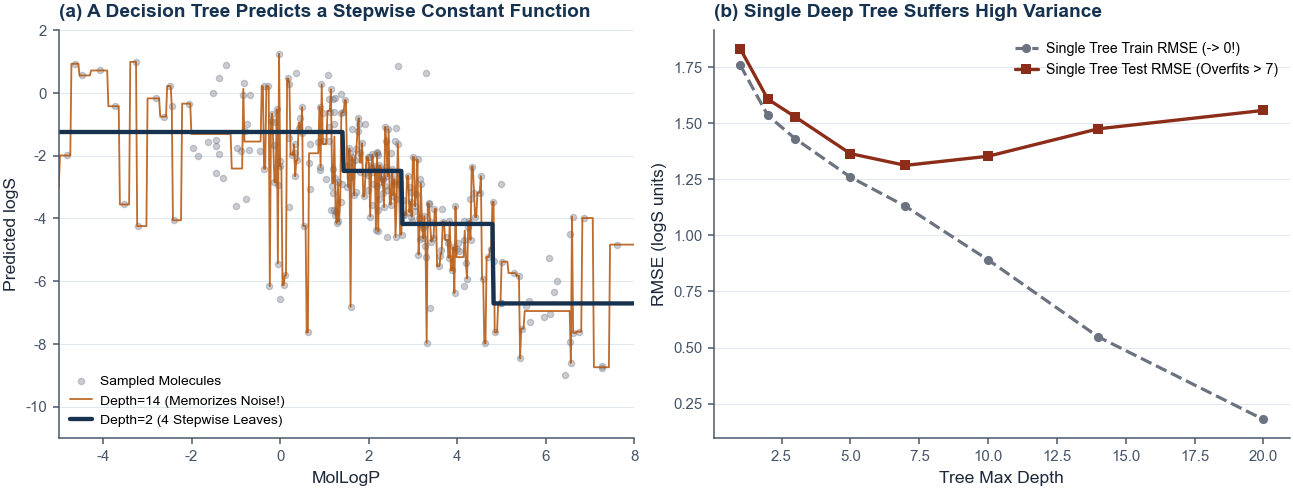

Single Tree (max_depth=7)    | 训练 RMSE = 1.130 | 测试 RMSE = 1.312 | 测试 R² = 0.706
Single Tree (Unlimited Depth) | 训练 RMSE = 0.056 | 测试 RMSE = 1.531 | 测试 R² = 0.599


In [6]:
# 可视化：(a) max_depth=2 的 4 段水平阶梯切分 vs 过深树锯齿；(b) 单棵树深度扫描的过拟合曲线
logp_idx = feature_cols.index("MolLogP")
x1_tr = X_train[:, [logp_idx]]
x1_grid = np.linspace(-5, 8, 500).reshape(-1, 1)

tree_d2 = DecisionTreeRegressor(max_depth=2, random_state=42).fit(x1_tr, y_train)
tree_deep = DecisionTreeRegressor(max_depth=14, random_state=42).fit(x1_tr[:300], y_train[:300])

depths = [1, 2, 3, 5, 7, 10, 14, 20]
tr_d, te_d = [], []
for d in depths:
    dt = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_train, y_train)
    tr_d.append(root_mean_squared_error(y_train, dt.predict(X_train)))
    te_d.append(root_mean_squared_error(y_test, dt.predict(X_test)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))

ax1.scatter(x1_tr[:300, 0], y_train[:300], s=14, alpha=0.35, color=C.slate, label="Sampled Molecules")
ax1.plot(x1_grid, tree_deep.predict(x1_grid), color=C.gold, lw=1.1, alpha=0.85, label="Depth=14 (Memorizes Noise!)")
ax1.plot(x1_grid, tree_d2.predict(x1_grid), color=C.navy, lw=2.6, label="Depth=2 (4 Stepwise Leaves)")
ax1.set_xlim(-5, 8)
ax1.set_ylim(-11, 2)
ax1.set_xlabel("MolLogP")
ax1.set_ylabel("Predicted logS")
ax1.set_title("(a) A Decision Tree Predicts a Stepwise Constant Function")
ax1.legend(fontsize=8.3, loc="lower left")

ax2.plot(depths, tr_d, "o--", color=C.slate, label="Single Tree Train RMSE (-> 0!)")
ax2.plot(depths, te_d, "s-", color=C.crimson, lw=2.0, label="Single Tree Test RMSE (Overfits > 7)")
ax2.set_xlabel("Tree Max Depth")
ax2.set_ylabel("RMSE (logS units)")
ax2.set_title("(b) Single Deep Tree Suffers High Variance")
ax2.legend(fontsize=8.5)

plt.show()

_ = evaluate_reg(DecisionTreeRegressor(max_depth=7, random_state=42), X_train, y_train, X_test, y_test, "Single Tree (max_depth=7)")
_ = evaluate_reg(DecisionTreeRegressor(max_depth=None, random_state=42), X_train, y_train, X_test, y_test, "Single Tree (Unlimited Depth)")

看到单棵树的尴尬了吗？浅树（`depth=2`）台阶太粗、欠拟合；不限深度的单棵树训练误差几乎降到 `0.03`，测试误差却反弹恶化到 **`1.53`**（比 kNN 和 SVR 差一大截）！怎样才能既保留深树的非线性表达力，又消掉它的剧烈抖动？答案是**集成学习（Ensemble Learning）**。

---
## 2. 集成学习两大流派：Bagging（随机森林）vs Boosting（XGBoost）

| 维度 | **Bagging 代表：随机森林（Random Forest）** | **Boosting 代表：梯度提升树（XGBoost / GBDT）** |
| :--- | :--- | :--- |
| **核心组织方式** | **并行民主投票**：每次有放回随机抽样（Bootstrap）+ 随机抽部分特征，**独立并行**种出几百棵深树，最后取平均 | **串行错题接力**：从很浅的树（如 `depth=4~6`）出发，**后一棵树专门去拟合前面所有树留下的残差（错题）**，逐步累加修正 |
| **主攻统计弱点** | **降方差（Reduce Variance）**：单棵深树虽然抖动大，但几百棵互不完全相同的树一取平均，随机噪声互相抵消！ | **降偏差（Reduce Bias）**：单棵浅树虽然粗糙，但乘以学习率 $\eta$ 一轮接一轮往残差方向打补丁，精度越来越高！ |
| **调参脾气** | 非常省心，树越多越稳，几乎不会因为树多而过拟合 | 上限往往略高于随机森林，但如果步长 `learning_rate` 太大或轮数过多会过拟合噪声 |

下面我们先用直观可视化看懂 Boosting“一步步削平残差”的过程，再在 AqSolDB 上对比随机森林与 XGBoost 的实力：

Random Forest (150 trees)    | 训练 RMSE = 0.420 | 测试 RMSE = 1.168 | 测试 R² = 0.767


XGBoost (300 trees, lr=0.05) | 训练 RMSE = 0.703 | 测试 RMSE = 1.153 | 测试 R² = 0.773


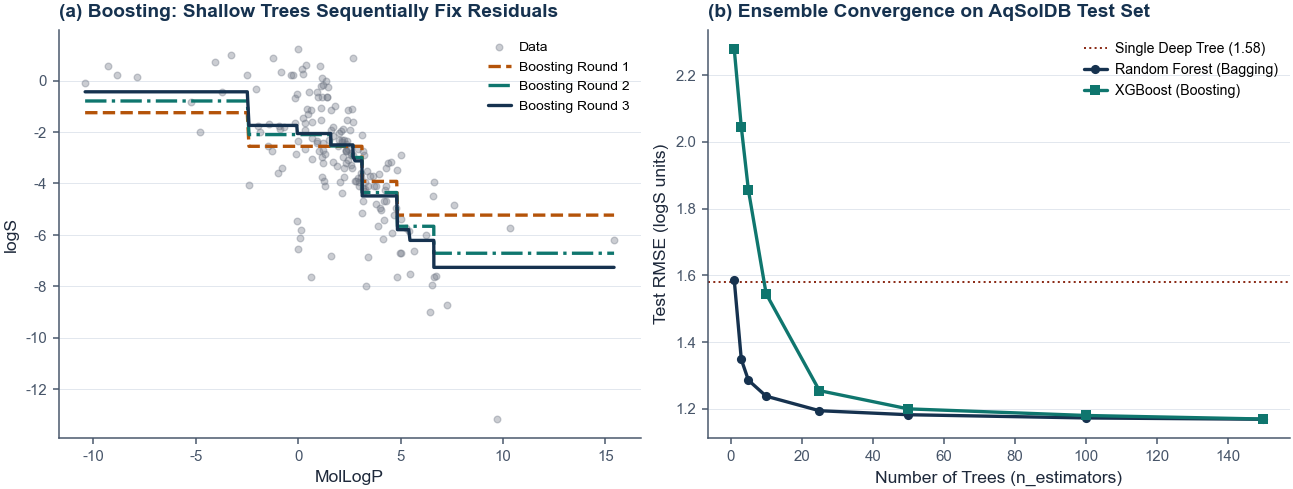

In [7]:
# ▶️ 运行看看：(a) 手写 3 轮梯度提升树残差修正直观演示；(b) AqSolDB 上 RF vs XGBoost 随树数增加的收敛曲线
x_demo = np.sort(x1_tr[:180, 0]).reshape(-1, 1)
# 取对应排序下标
order = np.argsort(x1_tr[:180, 0])
y_demo = y_train[:180][order]

# 演示 Boosting 串行拟合残差：y_hat^(t) = y_hat^(t-1) + lr * tree_t(x)
y_boost = np.full_like(y_demo, y_demo.mean())
lr_demo = 0.6
boost_snapshots = []
for step in range(1, 4):
    residual = y_demo - y_boost
    weak_tree = DecisionTreeRegressor(max_depth=2).fit(x_demo, residual)
    y_boost = y_boost + lr_demo * weak_tree.predict(x_demo)
    boost_snapshots.append((step, y_boost.copy()))

# 在完整 AqSolDB 上评估 Random Forest 与 XGBoost
rf = RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1)
rmse_rf = evaluate_reg(rf, X_train, y_train, X_test, y_test, "Random Forest (150 trees)")

xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)
rmse_xgb = evaluate_reg(xgb, X_train, y_train, X_test, y_test, "XGBoost (300 trees, lr=0.05)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))

ax1.scatter(x_demo[:, 0], y_demo, s=16, alpha=0.35, color=C.slate, label="Data")
for (step, snap), col, ls in zip(boost_snapshots, [C.gold, C.teal, C.navy], ["--", "-.", "-"]):
    ax1.plot(x_demo[:, 0], snap, color=col, linestyle=ls, lw=2.0, label=f"Boosting Round {step}")
ax1.set_xlabel("MolLogP")
ax1.set_ylabel("logS")
ax1.set_title("(a) Boosting: Shallow Trees Sequentially Fix Residuals")
ax1.legend(fontsize=8.3)

n_trees_list = [1, 3, 5, 10, 25, 50, 100, 150]
rf_curve = [
    root_mean_squared_error(y_test, RandomForestRegressor(n_estimators=n, random_state=42, n_jobs=-1).fit(X_train, y_train).predict(X_test))
    for n in n_trees_list
]
xgb_curve = [
    root_mean_squared_error(y_test, XGBRegressor(n_estimators=n, learning_rate=0.08, max_depth=6, random_state=42, n_jobs=-1).fit(X_train, y_train).predict(X_test))
    for n in n_trees_list
]

ax2.axhline(1.53, color=C.crimson, ls=":", lw=1.2, label="Single Deep Tree (1.53)")
ax2.plot(n_trees_list, rf_curve, "o-", color=C.navy, lw=2.0, label="Random Forest (Bagging)")
ax2.plot(n_trees_list, xgb_curve, "s-", color=C.teal, lw=2.0, label="XGBoost (Boosting)")
ax2.set_xlabel("Number of Trees (n_estimators)")
ax2.set_ylabel("Test RMSE (logS units)")
ax2.set_title("(b) Ensemble Convergence on AqSolDB Test Set")
ax2.legend(fontsize=8.5)

plt.show()

从单棵深树的 `1.53`，集成之后的随机森林（`1.17`）与 XGBoost（`1.14`）直接把测试集 RMSE 拉低了 `0.4` 个数量级以上！

---
## 3. 分子表示对比：物理化学描述符 vs 二值/计数分子指纹

兑现我们在 `01d` 留下的分子表示伏笔：
- **17 个描述符**直接给出了分子量、`MolLogP`、`TPSA` 等人类总结的宏观全局性质；
- **2048 维 Morgan 指纹**只编码局部半径 $r \le 2$ 的原子碎片，而且我们在 `01d` 发现**二值指纹（Bit FP，只记 0/1）**分不清并四苯和并五苯，**计数指纹（Count FP，记录局部碎片出现次数）**才能分清。

树模型不需要缩放，天生能直接吞下 2048 维稀疏指纹。我们实测对比这三种表示：

In [8]:
fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fp_count = np.array([fp_gen.GetCountFingerprintAsNumPy(m) for m in df["mol"]], dtype=np.float32)
fp_bit = (fp_count > 0).astype(np.float32)

fpb_tr, fpb_te = train_test_split(fp_bit, test_size=0.2, random_state=42)
fpc_tr, fpc_te = train_test_split(fp_count, test_size=0.2, random_state=42)

# 用并行高速的 XGBoost 公平对比三种输入表征
xgb_cfg = dict(n_estimators=250, learning_rate=0.06, max_depth=6, random_state=42, n_jobs=-1)
_ = evaluate_reg(XGBRegressor(**xgb_cfg), fpb_tr, y_train, fpb_te, y_test, "XGBoost + 2048 Bit FP")
_ = evaluate_reg(XGBRegressor(**xgb_cfg), fpc_tr, y_train, fpc_te, y_test, "XGBoost + 2048 Count FP")
_ = evaluate_reg(XGBRegressor(**xgb_cfg), X_train, y_train, X_test, y_test, "XGBoost + 17 Descriptors")

XGBoost + 2048 Bit FP        | 训练 RMSE = 1.130 | 测试 RMSE = 1.431 | 测试 R² = 0.650


XGBoost + 2048 Count FP      | 训练 RMSE = 0.947 | 测试 RMSE = 1.273 | 测试 R² = 0.723
XGBoost + 17 Descriptors     | 训练 RMSE = 0.708 | 测试 RMSE = 1.173 | 测试 R² = 0.765


实验结果完美印证了化学直觉：
1. **Count 指纹显著优于 Bit 指纹**：溶解度强烈依赖分子尺寸和重复基团个数，“有几个芳环/亚甲基”比单纯“有没有”关键得多；
2. **短短 17 个全局描述符仍然优于单用 2048 维局部碎片指纹**（而在下面练习中把两者拼起来，就能强强联合刷新最高分！）。

---
## 4. 实战推理：预测并苯系列与“树模型为什么无法外推”

现在我们用训练好的随机森林与 XGBoost 去预测有机场效应晶体管的经典母核——**并苯（Acene）系列**（从单环苯 `N=1` 到五环并五苯 `N=5`；注意 `N=1~4` 在 AqSolDB 库中，而**并五苯 `N=5` 不在库中**）：

 Rings    Molecule  Measured_logS   RF_Pred  XGB_Pred
     1     Benzene      -1.642309 -1.723369 -1.808143
     2 Naphthalene      -4.311226 -4.125940 -3.780737
     3  Anthracene      -6.444811 -6.014222 -5.646178
     4   Tetracene      -8.600000 -8.242884 -7.621676
     5   Pentacene            NaN -8.344242 -7.967861


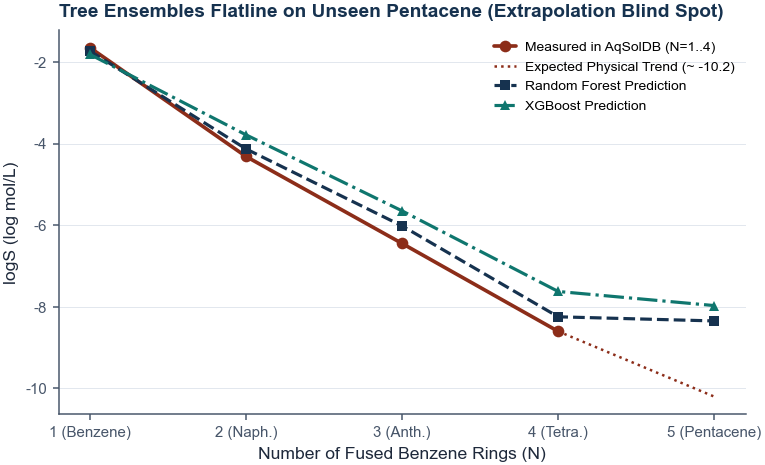

In [9]:
def featurize_smi(smi: str) -> np.ndarray:
    mol = Chem.MolFromSmiles(smi)
    return np.array([[getattr(Descriptors, name)(mol) for name in feature_cols]])

acenes = [
    (1, "Benzene",     "c1ccccc1"),
    (2, "Naphthalene", "c1ccc2ccccc2c1"),
    (3, "Anthracene",  "c1ccc2cc3ccccc3cc2c1"),
    (4, "Tetracene",   "c1ccc2cc3cc4ccccc4cc3cc2c1"),
    (5, "Pentacene",   "c1ccc2cc3cc4cc5ccccc5cc4cc3cc2c1"),
]

canon_map = dict(zip(df["mol"].apply(Chem.MolToSmiles), df["Solubility"]))
acene_rows = []
for n_ring, name, smi in acenes:
    canon = Chem.MolToSmiles(Chem.MolFromSmiles(smi))
    x_vec = featurize_smi(smi)
    acene_rows.append({
        "Rings": n_ring,
        "Molecule": name,
        "Measured_logS": canon_map.get(canon, np.nan),
        "RF_Pred": rf.predict(x_vec)[0],
        "XGB_Pred": xgb.predict(x_vec)[0],
    })

acene_df = pd.DataFrame(acene_rows)
print(acene_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(6.4, 3.9))
ax.plot(acene_df["Rings"], acene_df["Measured_logS"], "o-", color=C.crimson, lw=2.2, markersize=7, label="Measured in AqSolDB (N=1..4)")
ax.plot([4, 5], [acene_df.loc[3, "Measured_logS"], -10.2], ":", color=C.crimson, lw=1.5, label="Expected Physical Trend (~ -10.2)")
ax.plot(acene_df["Rings"], acene_df["RF_Pred"], "s--", color=C.navy, lw=1.9, label="Random Forest Prediction")
ax.plot(acene_df["Rings"], acene_df["XGB_Pred"], "^-.", color=C.teal, lw=1.9, label="XGBoost Prediction")
ax.set_xticks([1, 2, 3, 4, 5], ["1 (Benzene)", "2 (Naph.)", "3 (Anth.)", "4 (Tetra.)", "5 (Pentacene)"])
ax.set_xlabel("Number of Fused Benzene Rings (N)")
ax.set_ylabel("logS (log mol/L)")
ax.set_title("Tree Ensembles Flatline on Unseen Pentacene (Extrapolation Blind Spot)")
ax.legend(fontsize=8.3)
plt.show()

> **💡 彻底看懂为什么树模型在并五苯上“拐平”了**：
> 结合第 1 节我们亲手画出的**阶梯函数（图 1a）**，答案再清楚不过了：无论是随机森林还是 XGBoost，每棵树的叶子节点输出的都只是**落入该叶子的已知训练分子的平均值（或残差和）**。当并五苯的芳香环数和疏水性走出了训练数据密集区，它只能掉进最边缘的那个叶子里，原封不动拿到并四苯附近分子的溶解度（约 `-8.0`），**在数学结构上绝不可能顺着斜率继续往下推到 `-10.2`**！

---
### 🏋️ 练习 02c-1：诊断 XGBoost 的学习率与树深过拟合

如果把 XGBoost 的步长开得过大、树种得过深，串行纠错就会演变成“串行死记硬背噪声”。请实例化一个激进配置的 `XGBRegressor(n_estimators=300, learning_rate=0.4, max_depth=10, random_state=42, n_jobs=-1)`，调用 `evaluate_reg` 对比它与前面稳健配置（`learning_rate=0.05, max_depth=6`）的**训练 RMSE** 和**测试 RMSE**。（参考答案见 `solutions/02_supervised_solutions.ipynb`）

In [10]:
# 在这里写你的代码（练习 02c-1）


### 🏋️ 练习 02c-2：强强联合——拼接“17 个宏观描述符 + 2048 维计数指纹”

用 `np.hstack([X_train, fpc_tr])` 和 `np.hstack([X_test, fpc_te])` 构建 **2065 维混合特征矩阵**，训练一个 `XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.5, random_state=42, n_jobs=-1)`（或 `RandomForestRegressor`），看看测试集 RMSE 能否突破单用描述符或单用指纹的纪录！

In [11]:
# 在这里写你的代码（练习 02c-2）


---
## 小结

- **单棵决策树**：按加权 MSE（或基尼不纯度）贪心切分特征空间，天然免缩放，但深树方差极大易过拟合；
- **Bagging（随机森林）vs Boosting（XGBoost）**：前者并行平均深树以**降方差**，后者串行用浅树拟合残差以**降偏差**，是结构化材料特征表上的首选强基线；
- **表征与外推**：计数指纹优于二值指纹，宏观描述符 + 计数指纹互补最强；但时刻牢记所有树模型本质都是**分片常数内插器**，绝不能直接用于跨边界趋势外推。

**👉 下一节（`02d_classification.ipynb`）**：如果实验室不需要预测精确到小数点后两位的溶解度，而是想做**“难溶 vs 可溶”高通量二分类筛查**呢？我们将从手写**感知机（Perceptron）**出发，进入**逻辑回归概率预测、ROC-AUC 评估体系与 Yalkowsky 物理化学归因**！